# Regresja liniowa

W modelu liniowym zależność między $Y$ a $X_1, ..., X_p$ modelujemy jako:

$$Y=\beta_0 + \beta_1 X_1 + ... + \beta_p X_p + \epsilon$$

Wartości współczynników $\beta_0, ..., \beta_p$ szacowane są metodą "najmniejszych kwadratów", w której zminimalizowa jest wartość $RSS$ (*Residual Sum of Squares*):

$$RSS=\sum_{i = 1}^n (y_i - \hat{y_i})^2$$



## Model liniowy w `statsmodels`

Wykorzystamy zbiór [mtcars](https://www.rdocumentation.org/packages/datasets/versions/3.6.2/topics/mtcars).
W pierwszym przykładzie tworzymy model w postaci: 

$$ \mathtt{mpg} = \hat{\beta_0} + \hat{\beta_1} \mathtt{hp} $$

In [19]:
import pandas as pd
import statsmodels.api as sm

df = pd.read_csv("mtcars.csv")

y = df.mpg
X = sm.add_constant(df.hp)

print(X.head())
print()
print(y.head())

   const   hp
0    1.0  110
1    1.0  110
2    1.0   93
3    1.0  110
4    1.0  175

0    21.0
1    21.0
2    22.8
3    21.4
4    18.7
Name: mpg, dtype: float64


In [20]:
lm = sm.OLS(y, X)
lm_fit = lm.fit()

Procedura `fit` zwraca obiekt typu [`RegressionResults`](https://www.statsmodels.org/dev/generated/statsmodels.regression.linear_model.RegressionResults.html).

W podsumowaniu (`summary()`) podane są m.in. wartość $R^2$ oraz $p$-wartości szacowanych współczynników.

In [21]:
lm_fit.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    mpg   R-squared:                       0.602
Model:                            OLS   Adj. R-squared:                  0.589
Method:                 Least Squares   F-statistic:                     45.46
Date:                Sat, 21 Nov 2026   Prob (F-statistic):           1.79e-07
Time:                        19:31:58   Log-Likelihood:                -87.619
No. Observations:                  32   AIC:                             179.2
Df Residuals:                      30   BIC:                             182.2
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         30.0989      1.634     18.421      0.000      26.762      33.436
hp            -0.0682      0.010     -6.742      0.000      -0.089      -0.048
==============================================================================
Omnibus:                        3.692   Durbin-Watson:                   1.134
Prob(Omnibus):                  0.158   Jarque-Bera (JB):                2.984
Skew:                           0.747   Prob(JB):                        0.225
Kurtosis:                       2.935   Cond. No.                         386.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

Współczynniki $\hat{\beta_0}$ i $\hat{\beta_1}$ zapisane są w `lm_fit.params`.

In [22]:
lm_fit.params

const    30.098861
hp       -0.068228
dtype: float64

Reszty (*residuals*) zapisane są w `lm_fit.resid`.

In [23]:
lm_fit.resid.head()

0   -1.593750
1   -1.593750
2   -0.953631
3   -1.193750
4    0.541088
dtype: float64

W ocenie modelu przydatna jest także wizualizacja.

Text(0, 0.5, 'Residual')

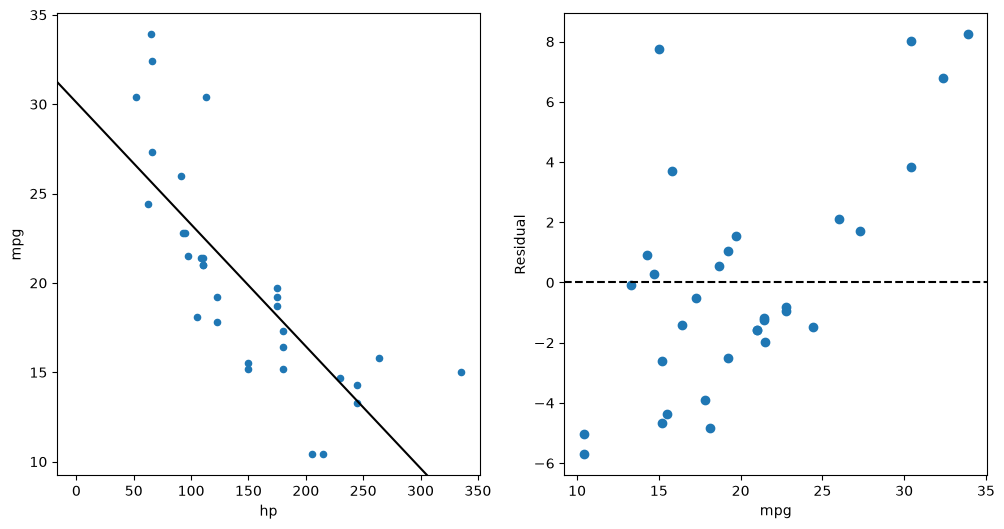

In [24]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

df.plot(kind='scatter', y='mpg', x='hp', ax=ax1)
(b0, b1) = lm_fit.params

ax1.axline(xy1=(0,b0), slope=b1, color='k')

ax2.scatter(df.mpg, lm_fit.resid)
ax2.axhline(0, linestyle='--', color='k')
ax2.set_xlabel('mpg')
ax2.set_ylabel('Residual')

Metoda `predict()` pozwala na predykcję wartości `mpg` dla nowych danych.

In [25]:
X_new = sm.add_constant([100, 150])
y_pred = lm_fit.predict(X_new)
y_pred

array([23.27603273, 19.86461883])

Tworząc model zawierający wiele zmiennych możemy skorzystać z `statsmodels.formula.api`, które pozwala podać 'wzór' modelu zamiast manualnie przygotowywać dane wejściowe. 
$$ \mathtt{mpg} = \hat{\beta_0} + \hat{\beta_1} \mathtt{hp} + \hat{\beta_2} \mathtt{cyl}$$

In [26]:
import statsmodels.formula.api as smf

lm1 = smf.ols(formula="mpg ~ hp + cyl", data=df)
lm_fit1 = lm1.fit()
lm_fit1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    mpg   R-squared:                       0.741
Model:                            OLS   Adj. R-squared:                  0.723
Method:                 Least Squares   F-statistic:                     41.42
Date:                Sat, 21 Nov 2026   Prob (F-statistic):           3.16e-09
Time:                        19:31:59   Log-Likelihood:                -80.781
No. Observations:                  32   AIC:                             167.6
Df Residuals:                      29   BIC:                             172.0
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     36.9083      2.191     16.847      0.000      32.428      41.389
hp            -0.0191      0.015     -1.275      0.213      -0.050       0.012
cyl           -2.2647      0.576     -3.933      0.000      -3.443      -1.087
==============================================================================
Omnibus:                        1.178   Durbin-Watson:                   1.667
Prob(Omnibus):                  0.555   Jarque-Bera (JB):                1.092
Skew:                           0.411   Prob(JB):                        0.579
Kurtosis:                       2.623   Cond. No.                         645.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

Względem poprzedniego modelu wartość $R^2$ wzrosła z $0.602$ do $0.741$. Zwróćmy uwagę, że $p$-wartość współczynnika `hp` wynosi 0.213, co sugeruje, że nie ma zależności między `mpg` a `hp`, mimo że wykryliśmy taką zależność w modelu jednoczynnikowym. Jest to spowodowane liniową współzależnością między zmiennymi.

<Axes: >

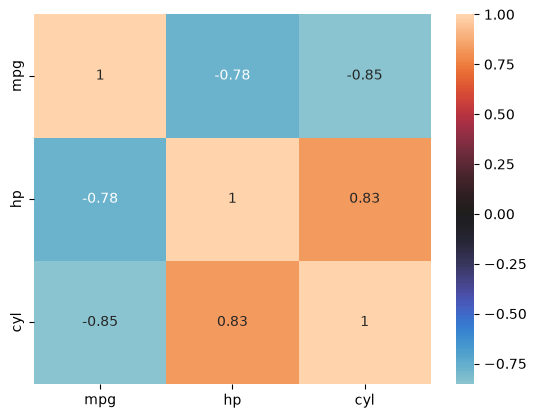

In [27]:
import seaborn as sns
sns.heatmap(df[["mpg", "hp", "cyl"]].corr(), annot=True, center=0.0)

Rozważmy alternatywny model:

$$ \mathtt{mpg} = \hat{\beta_0} + \hat{\beta_1} \mathtt{hp} + \hat{\beta_2} \mathtt{wt}$$

In [28]:
lm2 = smf.ols(formula="mpg ~ hp + wt", data=df)
lm_fit2 = lm2.fit()
lm_fit2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    mpg   R-squared:                       0.827
Model:                            OLS   Adj. R-squared:                  0.815
Method:                 Least Squares   F-statistic:                     69.21
Date:                Sat, 21 Nov 2026   Prob (F-statistic):           9.11e-12
Time:                        19:31:59   Log-Likelihood:                -74.326
No. Observations:                  32   AIC:                             154.7
Df Residuals:                      29   BIC:                             159.0
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     37.2273      1.599     23.285      0.000      33.957      40.497
hp            -0.0318      0.009     -3.519      0.001      -0.050      -0.013
wt            -3.8778      0.633     -6.129      0.000      -5.172      -2.584
==============================================================================
Omnibus:                        5.303   Durbin-Watson:                   1.362
Prob(Omnibus):                  0.071   Jarque-Bera (JB):                4.046
Skew:                           0.855   Prob(JB):                        0.132
Kurtosis:                       3.332   Cond. No.                         588.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

## Model wielomianowy

W rozważanym wcześniej modelu `mpg ~ hp` faktyczny rozkład danych widoczny na wykresie jest wyraźnie nieliniowy. Sprawdźmy, czy poniższy model wielomianowy lepiej odwzoruje zależność między `mpg` a `hp`. 

$$ \mathtt{mpg} = \hat{\beta_0} + \hat{\beta_1} \mathtt{hp} + \hat{\beta_2} \mathtt{hp}^2$$

In [29]:
lm3 = smf.ols(formula="mpg ~ hp + I(hp**2)", data=df)

lm_fit3 = lm3.fit()

lm_fit3.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    mpg   R-squared:                       0.756
Model:                            OLS   Adj. R-squared:                  0.739
Method:                 Least Squares   F-statistic:                     44.95
Date:                Sat, 21 Nov 2026   Prob (F-statistic):           1.30e-09
Time:                        19:31:59   Log-Likelihood:                -79.801
No. Observations:                  32   AIC:                             165.6
Df Residuals:                      29   BIC:                             170.0
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     40.4091      2.741     14.744      0.000      34.804      46.015
hp            -0.2133      0.035     -6.115      0.000      -0.285      -0.142
I(hp ** 2)     0.0004   9.84e-05      4.275      0.000       0.000       0.001
==============================================================================
Omnibus:                        6.211   Durbin-Watson:                   1.697
Prob(Omnibus):                  0.045   Jarque-Bera (JB):                4.579
Skew:                           0.844   Prob(JB):                        0.101
Kurtosis:                       3.767   Cond. No.                     1.78e+05
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.78e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

Text(0, 0.5, 'residual')

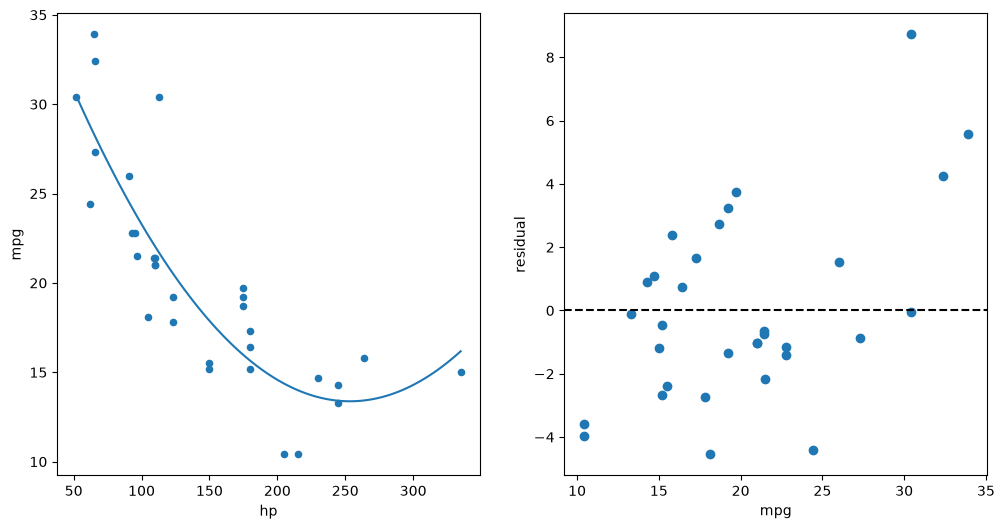

In [30]:
import numpy as np
import patsy

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))
df.plot(kind='scatter', y='mpg', x='hp', ax=ax1)

x_plot = np.linspace(df.hp.min(), df.hp.max(), 100)
X_plot = patsy.dmatrix(" ~ 1 + hp + I(hp**2)", data={"hp": x_plot}, return_type='dataframe')
y_plot = lm_fit3.predict(X_plot)

ax1.plot(x_plot, y_plot)

ax2.scatter(df.mpg, lm_fit3.resid)
ax2.axhline(0, linestyle='--', color='k')
ax2.set_xlabel('mpg')
ax2.set_ylabel('residual')

## Modelowanie interakcji między zmiennymi

$$ \mathtt{mpg} = \hat{\beta_0} + \hat{\beta_1} \mathtt{hp} + \hat{\beta_2} \mathtt{wt} + \hat{\beta_3} \mathtt{hp} \cdot \mathtt{wt}$$

In [31]:
lm4 = smf.ols(formula="mpg ~ hp + wt + hp:wt", data=df) # Możemy też wykorzystać formula="mpg ~ hp*wt"

lm_fit4 = lm4.fit()

lm_fit4.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    mpg   R-squared:                       0.885
Model:                            OLS   Adj. R-squared:                  0.872
Method:                 Least Squares   F-statistic:                     71.66
Date:                Sat, 21 Nov 2026   Prob (F-statistic):           2.98e-13
Time:                        19:31:59   Log-Likelihood:                -67.805
No. Observations:                  32   AIC:                             143.6
Df Residuals:                      28   BIC:                             149.5
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     49.8084      3.605     13.816      0.000      42.424      57.193
hp            -0.1201      0.025     -4.863      0.000      -0.171      -0.070
wt            -8.2166      1.270     -6.471      0.000     -10.818      -5.616
hp:wt          0.0278      0.007      3.753      0.001       0.013       0.043
==============================================================================
Omnibus:                        2.221   Durbin-Watson:                   2.128
Prob(Omnibus):                  0.329   Jarque-Bera (JB):                1.736
Skew:                           0.407   Prob(JB):                        0.420
Kurtosis:                       2.200   Cond. No.                     6.35e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 6.35e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

## Zadania

### 1. Boston - przewidywanie mediany wartości domów

Wczytaj zbiór danych w pliku `boston.csv` ([opis](https://www.rdocumentation.org/packages/MASS/versions/7.3-58.3/topics/Boston)), a następnie modeluj zależność `medv` od pozostałych zmiennych.
- Testuj kilka modeli (z jedną lub wieloma zmiennymi) i wybierz najlepszy. Dokonując manualnej selekcji modelu warto wstępnie zwizualizować macierz korelacji między zmiennymi. Można też skorzystać z metod forward/backward selection.
- Porównując modele, wykorzystaj `summary()`, aby sprawdzić $R^2$ modelu i $p$-wartośći współczynników.
- Wizualizuj modele (np. *residual plot*).
- Bonus: modeluj także zależności nieliniowe (np. wielomianowe) i/lub interakcje między zmiennymi.

<Axes: >

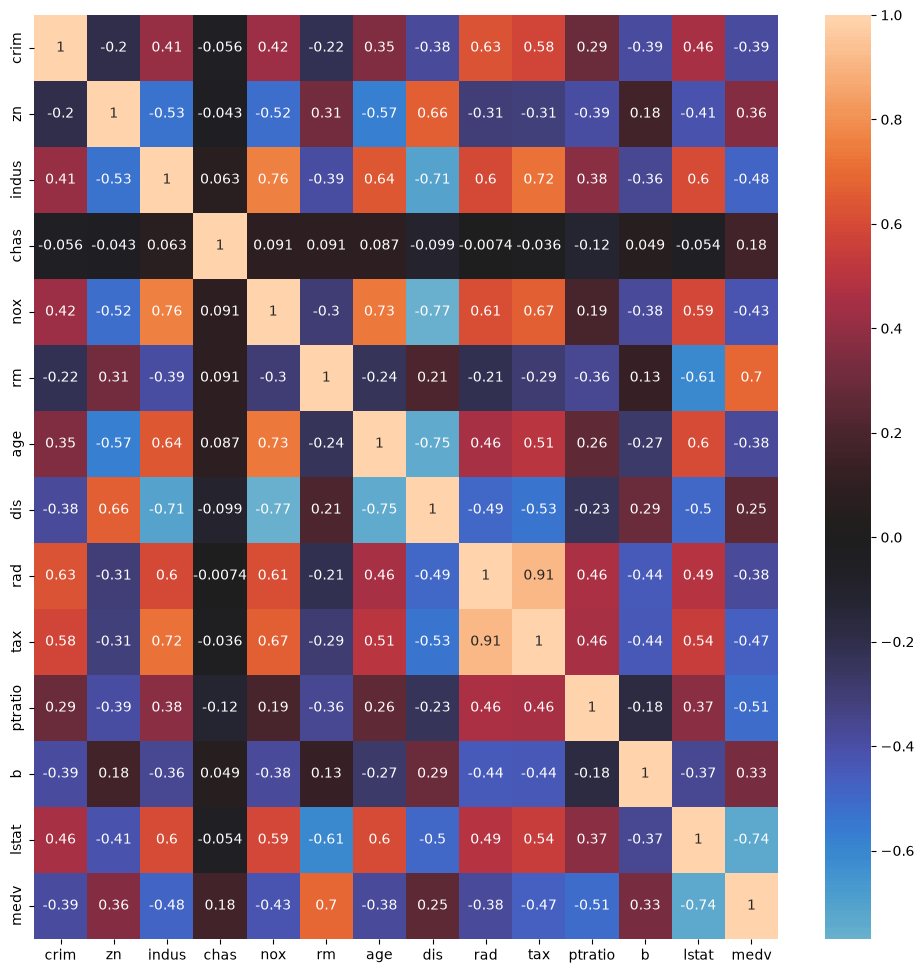

In [32]:
import seaborn as sns
# 1. Wczytanie danych Boston i macierz korelacji
df = pd.read_csv("boston.csv")
fig, ax = plt.subplots(figsize=(12,12))
sns.heatmap(df.corr(), annot=True, center=0.0, ax=ax)

Jedna zmienna
                            OLS Regression Results                            
Dep. Variable:                   medv   R-squared:                       0.557
Model:                            OLS   Adj. R-squared:                  0.556
Method:                 Least Squares   F-statistic:                     507.5
Date:                Sat, 21 Nov 2026   Prob (F-statistic):           2.48e-73
Time:                        19:32:00   Log-Likelihood:                -1315.2
No. Observations:                 405   AIC:                             2634.
Df Residuals:                     403   BIC:                             2642.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     34.7982      0.628     5

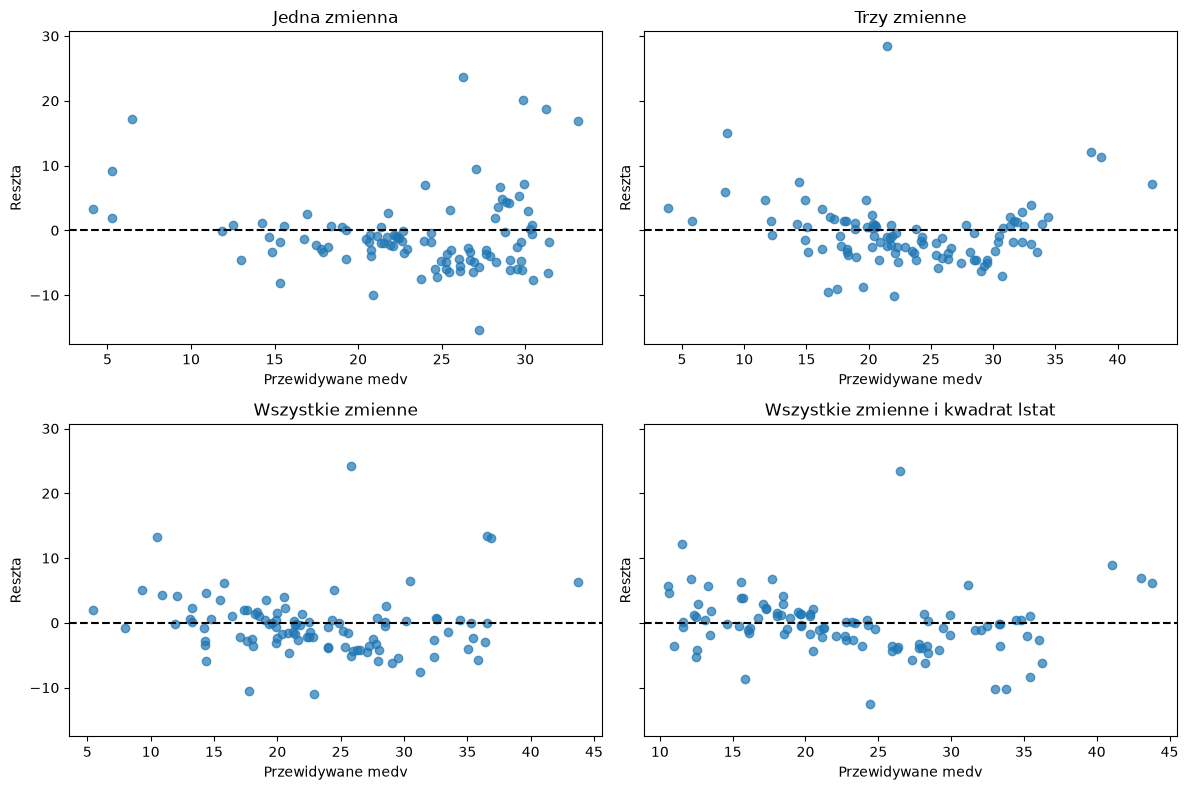

Najmniejszy RMSE na zbiorze testowym: Wszystkie zmienne i kwadrat lstat


,Model,R²,Skorygowane R²,RMSE (test)
3,Wszystkie zmienne i kwadrat lstat,0.806,0.799,4.642
2,Wszystkie zmienne,0.750,0.742,4.742
1,Trzy zmienne,0.685,0.683,5.057
0,Jedna zmienna,0.557,0.556,6.129


In [33]:
boston = df
boston_train = boston.sample(frac=0.8, random_state=42)
boston_test = boston.drop(index=boston_train.index)
boston_features = boston.columns.drop("medv")

# 1. Porównywane modele, w tym wariant nieliniowy z kwadratem lstat
formulas = {
    "Jedna zmienna": "medv ~ lstat",
    "Trzy zmienne": "medv ~ lstat + rm + ptratio",
    "Wszystkie zmienne": "medv ~ " + " + ".join(boston_features),
    "Wszystkie zmienne i kwadrat lstat": (
        "medv ~ " + " + ".join(boston_features) + " + I(lstat ** 2)"
    ),
}

results = []
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
for ax, (name, formula) in zip(axes.flat, formulas.items()):
    # 1. Dopasowanie modelu i obliczenie RMSE na zbiorze testowym
    model = smf.ols(formula, data=boston_train).fit()
    predicted = model.predict(boston_test)
    residuals = boston_test["medv"] - predicted
    rmse = residuals.pow(2).mean() ** 0.5
    results.append((name, model.rsquared, model.rsquared_adj, rmse))
    print(name)
    # 1. Podsumowanie z R² i p-wartościami współczynników
    print(model.summary())

    # 1. Wykres reszt względem przewidywanych wartości
    ax.scatter(predicted, residuals, alpha=0.7)
    ax.axhline(0, color="black", linestyle="--")
    ax.set(title=name, xlabel="Przewidywane medv", ylabel="Reszta")

fig.tight_layout()
plt.show()

# 1. Wybór modelu z najmniejszym testowym RMSE
comparison = pd.DataFrame(results, columns=["Model", "R²", "Skorygowane R²", "RMSE (test)"]).sort_values("RMSE (test)")
best_name = comparison.iloc[0]["Model"]
print(f"Najmniejszy RMSE na zbiorze testowym: {best_name}")
comparison.round(3)

### 2. Housing

Wczytaj zbiór danych w pliku `housing.csv`, 
- Usuń wiersze zawierające brakujące dane (lub zastąp wartością średnią).
- Koduj zmienną `ocean_proximity` (np. metodą `get_dummies()`).
- Modeluj zależność `median_house_value` od `ocean_proximity`.

In [34]:
# 2. Wczytanie danych Housing i usunięcie wierszy z brakami
housing = pd.read_csv("housing.csv").dropna()
# 2. Kodowanie ocean_proximity z kategorią odniesienia INLAND i dopasowanie modelu
housing_model = smf.ols(
    "median_house_value ~ C(ocean_proximity, Treatment('INLAND'))",
    data=housing,
).fit()
housing_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:     median_house_value   R-squared:                       0.238
Model:                            OLS   Adj. R-squared:                  0.238
Method:                 Least Squares   F-statistic:                     1595.
Date:                Sat, 21 Nov 2026   Prob (F-statistic):               0.00
Time:                        19:32:00   Log-Likelihood:            -2.6439e+05
No. Observations:               20433   AIC:                         5.288e+05
Df Residuals:                   20428   BIC:                         5.288e+05
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
=========================================================================================================================
                                                            coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------------------------
Intercept                                              1.249e+05   1250.402     99.885      0.000    1.22e+05    1.27e+05
C(ocean_proximity, Treatment('INLAND'))[T.<1H OCEAN]   1.154e+05   1639.439     70.372      0.000    1.12e+05    1.19e+05
C(ocean_proximity, Treatment('INLAND'))[T.ISLAND]      2.555e+05   4.51e+04      5.668      0.000    1.67e+05    3.44e+05
C(ocean_proximity, Treatment('INLAND'))[T.NEAR BAY]    1.344e+05   2457.183     54.690      0.000     1.3e+05    1.39e+05
C(ocean_proximity, Treatment('INLAND'))[T.NEAR OCEAN]  1.241e+05   2329.859     53.285      0.000     1.2e+05    1.29e+05
==============================================================================
Omnibus:                     2642.118   Durbin-Watson:                   0.415
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             3813.790
Skew:                           0.989   Prob(JB):                         0.00
Kurtosis:                       3.754   Cond. No.                         71.9
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""